# Matplotlib and Seaborn

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import calendar

### Loading Data

In [7]:
austin = pd.read_csv(r"C:\Users\Owner\Desktop\PYTHON-NOTES\Data\austin_weather.csv")

In [8]:
austin.head()

,STATION,NAME,DATE,MLY-CLDD-BASE45,MLY-CLDD-BASE50,MLY-CLDD-BASE55,MLY-CLDD-BASE57,MLY-CLDD-BASE60,MLY-CLDD-BASE70,MLY-CLDD-BASE72,...,MLY-TMIN-AVGNDS-LSTH060,MLY-TMIN-AVGNDS-LSTH070,MLY-TMIN-NORMAL,MLY-TMIN-PRBOCC-LSTH016,MLY-TMIN-PRBOCC-LSTH020,MLY-TMIN-PRBOCC-LSTH024,MLY-TMIN-PRBOCC-LSTH028,MLY-TMIN-PRBOCC-LSTH032,MLY-TMIN-PRBOCC-LSTH036,MLY-TMIN-STDDEV
0,USW00013904,"AUSTIN BERGSTROM INTERNATIONAL AIRPORT, TX US",1,190,103,50,35,18,1,-7777,...,302,310,36.3,298,570,839,967,997,1000,2.9
1,USW00013904,"AUSTIN BERGSTROM INTERNATIONAL AIRPORT, TX US",2,228,132,68,49,29,3,1,...,264,280,39.4,103,327,614,867,973,999,3.2
2,USW00013904,"AUSTIN BERGSTROM INTERNATIONAL AIRPORT, TX US",3,446,306,185,146,98,13,6,...,270,308,46.6,10,73,242,494,761,928,3.6
3,USW00013904,"AUSTIN BERGSTROM INTERNATIONAL AIRPORT, TX US",4,668,519,373,318,240,53,32,...,193,287,54.7,0,0,0,48,189,453,4.1
4,USW00013904,"AUSTIN BERGSTROM INTERNATIONAL AIRPORT, TX US",5,936,781,626,564,471,181,134,...,89,250,63.7,0,0,0,0,0,0,2.5


In [9]:
seattle = pd.read_csv(r"C:\Users\Owner\Desktop\PYTHON-NOTES\Data\seattle_weather.csv")

In [10]:
seattle.head()

,STATION,NAME,DATE,MLY-CLDD-BASE45,MLY-CLDD-BASE50,MLY-CLDD-BASE55,MLY-CLDD-BASE57,MLY-CLDD-BASE60,MLY-CLDD-BASE70,MLY-CLDD-BASE72,...,MLY-TMIN-AVGNDS-LSTH060,MLY-TMIN-AVGNDS-LSTH070,MLY-TMIN-NORMAL,MLY-TMIN-PRBOCC-LSTH016,MLY-TMIN-PRBOCC-LSTH020,MLY-TMIN-PRBOCC-LSTH024,MLY-TMIN-PRBOCC-LSTH028,MLY-TMIN-PRBOCC-LSTH032,MLY-TMIN-PRBOCC-LSTH036,MLY-TMIN-STDDEV
0,USC00456295,"PALMER 3 ESE, WA US",1,13.0,1.0,-7777.0,0.0,0.0,0.0,0.0,...,310.0,310.0,34.0,168.0,327.0,615.0,877.0,987.0,1000.0,2.8
1,USC00456295,"PALMER 3 ESE, WA US",2,23.0,3.0,-7777.0,-7777.0,0.0,0.0,0.0,...,280.0,280.0,33.9,132.0,275.0,515.0,800.0,963.0,1000.0,3.1
2,USC00456295,"PALMER 3 ESE, WA US",3,50.0,11.0,1.0,-7777.0,-7777.0,0.0,0.0,...,310.0,310.0,35.9,5.0,47.0,111.0,393.0,848.0,1000.0,2.1
3,USC00456295,"PALMER 3 ESE, WA US",4,108.0,40.0,12.0,7.0,3.0,-7777.0,0.0,...,300.0,300.0,38.3,0.0,0.0,5.0,123.0,571.0,978.0,2.0
4,USC00456295,"PALMER 3 ESE, WA US",5,255.0,130.0,56.0,38.0,19.0,1.0,-7777.0,...,310.0,310.0,43.5,0.0,0.0,0.0,0.0,83.0,610.0,2.0


### Data Cleaning and EDA

##### Cleaning and EDA for Seattle

In [11]:
# Checking for Missing Values in the seattle_csv dataset
seattle.isna().sum()

STATION                     0
NAME                        0
DATE                        0
MLY-CLDD-BASE45            24
MLY-CLDD-BASE50            24
                           ..
MLY-TMIN-PRBOCC-LSTH024    24
MLY-TMIN-PRBOCC-LSTH028    24
MLY-TMIN-PRBOCC-LSTH032    24
MLY-TMIN-PRBOCC-LSTH036    24
MLY-TMIN-STDDEV            24
Length: 80, dtype: int64

In [12]:
# Checking for Duplicates in the seattle_csv dataset
seattle.duplicated().sum()

np.int64(0)

In [13]:
seattle.info()

<class 'pandas.DataFrame'>
RangeIndex: 204 entries, 0 to 203
Data columns (total 80 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   STATION                  204 non-null    str    
 1   NAME                     204 non-null    str    
 2   DATE                     204 non-null    int64  
 3   MLY-CLDD-BASE45          180 non-null    float64
 4   MLY-CLDD-BASE50          180 non-null    float64
 5   MLY-CLDD-BASE55          180 non-null    float64
 6   MLY-CLDD-BASE57          180 non-null    float64
 7   MLY-CLDD-BASE60          180 non-null    float64
 8   MLY-CLDD-BASE70          180 non-null    float64
 9   MLY-CLDD-BASE72          180 non-null    float64
 10  MLY-CLDD-NORMAL          180 non-null    float64
 11  MLY-DUTR-NORMAL          180 non-null    float64
 12  MLY-DUTR-STDDEV          180 non-null    float64
 13  MLY-GRDD-BASE40          180 non-null    float64
 14  MLY-GRDD-BASE45          180 non-null

In [14]:
# Craete a new column on both dataframes called "month" that contains the month of the date column 
# eg 1 = Jan 2 = Feb .. , 11 = Nov , 12 = Dec

seattle["MONTH"] = seattle["DATE"].apply(lambda x: calendar.month_abbr[x])

In [15]:
seattle.head()

,STATION,NAME,DATE,MLY-CLDD-BASE45,MLY-CLDD-BASE50,MLY-CLDD-BASE55,MLY-CLDD-BASE57,MLY-CLDD-BASE60,MLY-CLDD-BASE70,MLY-CLDD-BASE72,...,MLY-TMIN-AVGNDS-LSTH070,MLY-TMIN-NORMAL,MLY-TMIN-PRBOCC-LSTH016,MLY-TMIN-PRBOCC-LSTH020,MLY-TMIN-PRBOCC-LSTH024,MLY-TMIN-PRBOCC-LSTH028,MLY-TMIN-PRBOCC-LSTH032,MLY-TMIN-PRBOCC-LSTH036,MLY-TMIN-STDDEV,MONTH
0,USC00456295,"PALMER 3 ESE, WA US",1,13.0,1.0,-7777.0,0.0,0.0,0.0,0.0,...,310.0,34.0,168.0,327.0,615.0,877.0,987.0,1000.0,2.8,Jan
1,USC00456295,"PALMER 3 ESE, WA US",2,23.0,3.0,-7777.0,-7777.0,0.0,0.0,0.0,...,280.0,33.9,132.0,275.0,515.0,800.0,963.0,1000.0,3.1,Feb
2,USC00456295,"PALMER 3 ESE, WA US",3,50.0,11.0,1.0,-7777.0,-7777.0,0.0,0.0,...,310.0,35.9,5.0,47.0,111.0,393.0,848.0,1000.0,2.1,Mar
3,USC00456295,"PALMER 3 ESE, WA US",4,108.0,40.0,12.0,7.0,3.0,-7777.0,0.0,...,300.0,38.3,0.0,0.0,5.0,123.0,571.0,978.0,2.0,Apr
4,USC00456295,"PALMER 3 ESE, WA US",5,255.0,130.0,56.0,38.0,19.0,1.0,-7777.0,...,310.0,43.5,0.0,0.0,0.0,0.0,83.0,610.0,2.0,May


### The pyplot interface

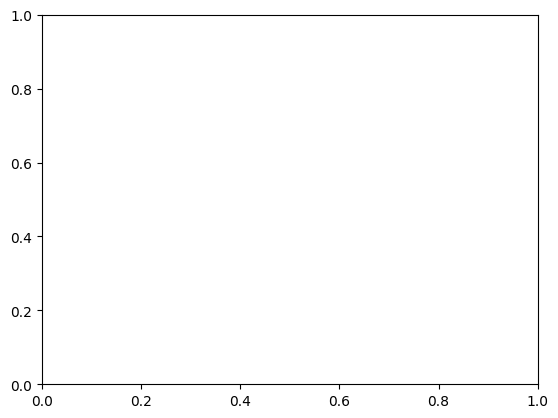

In [16]:
fig, sx = plt.subplots()
plt.show()

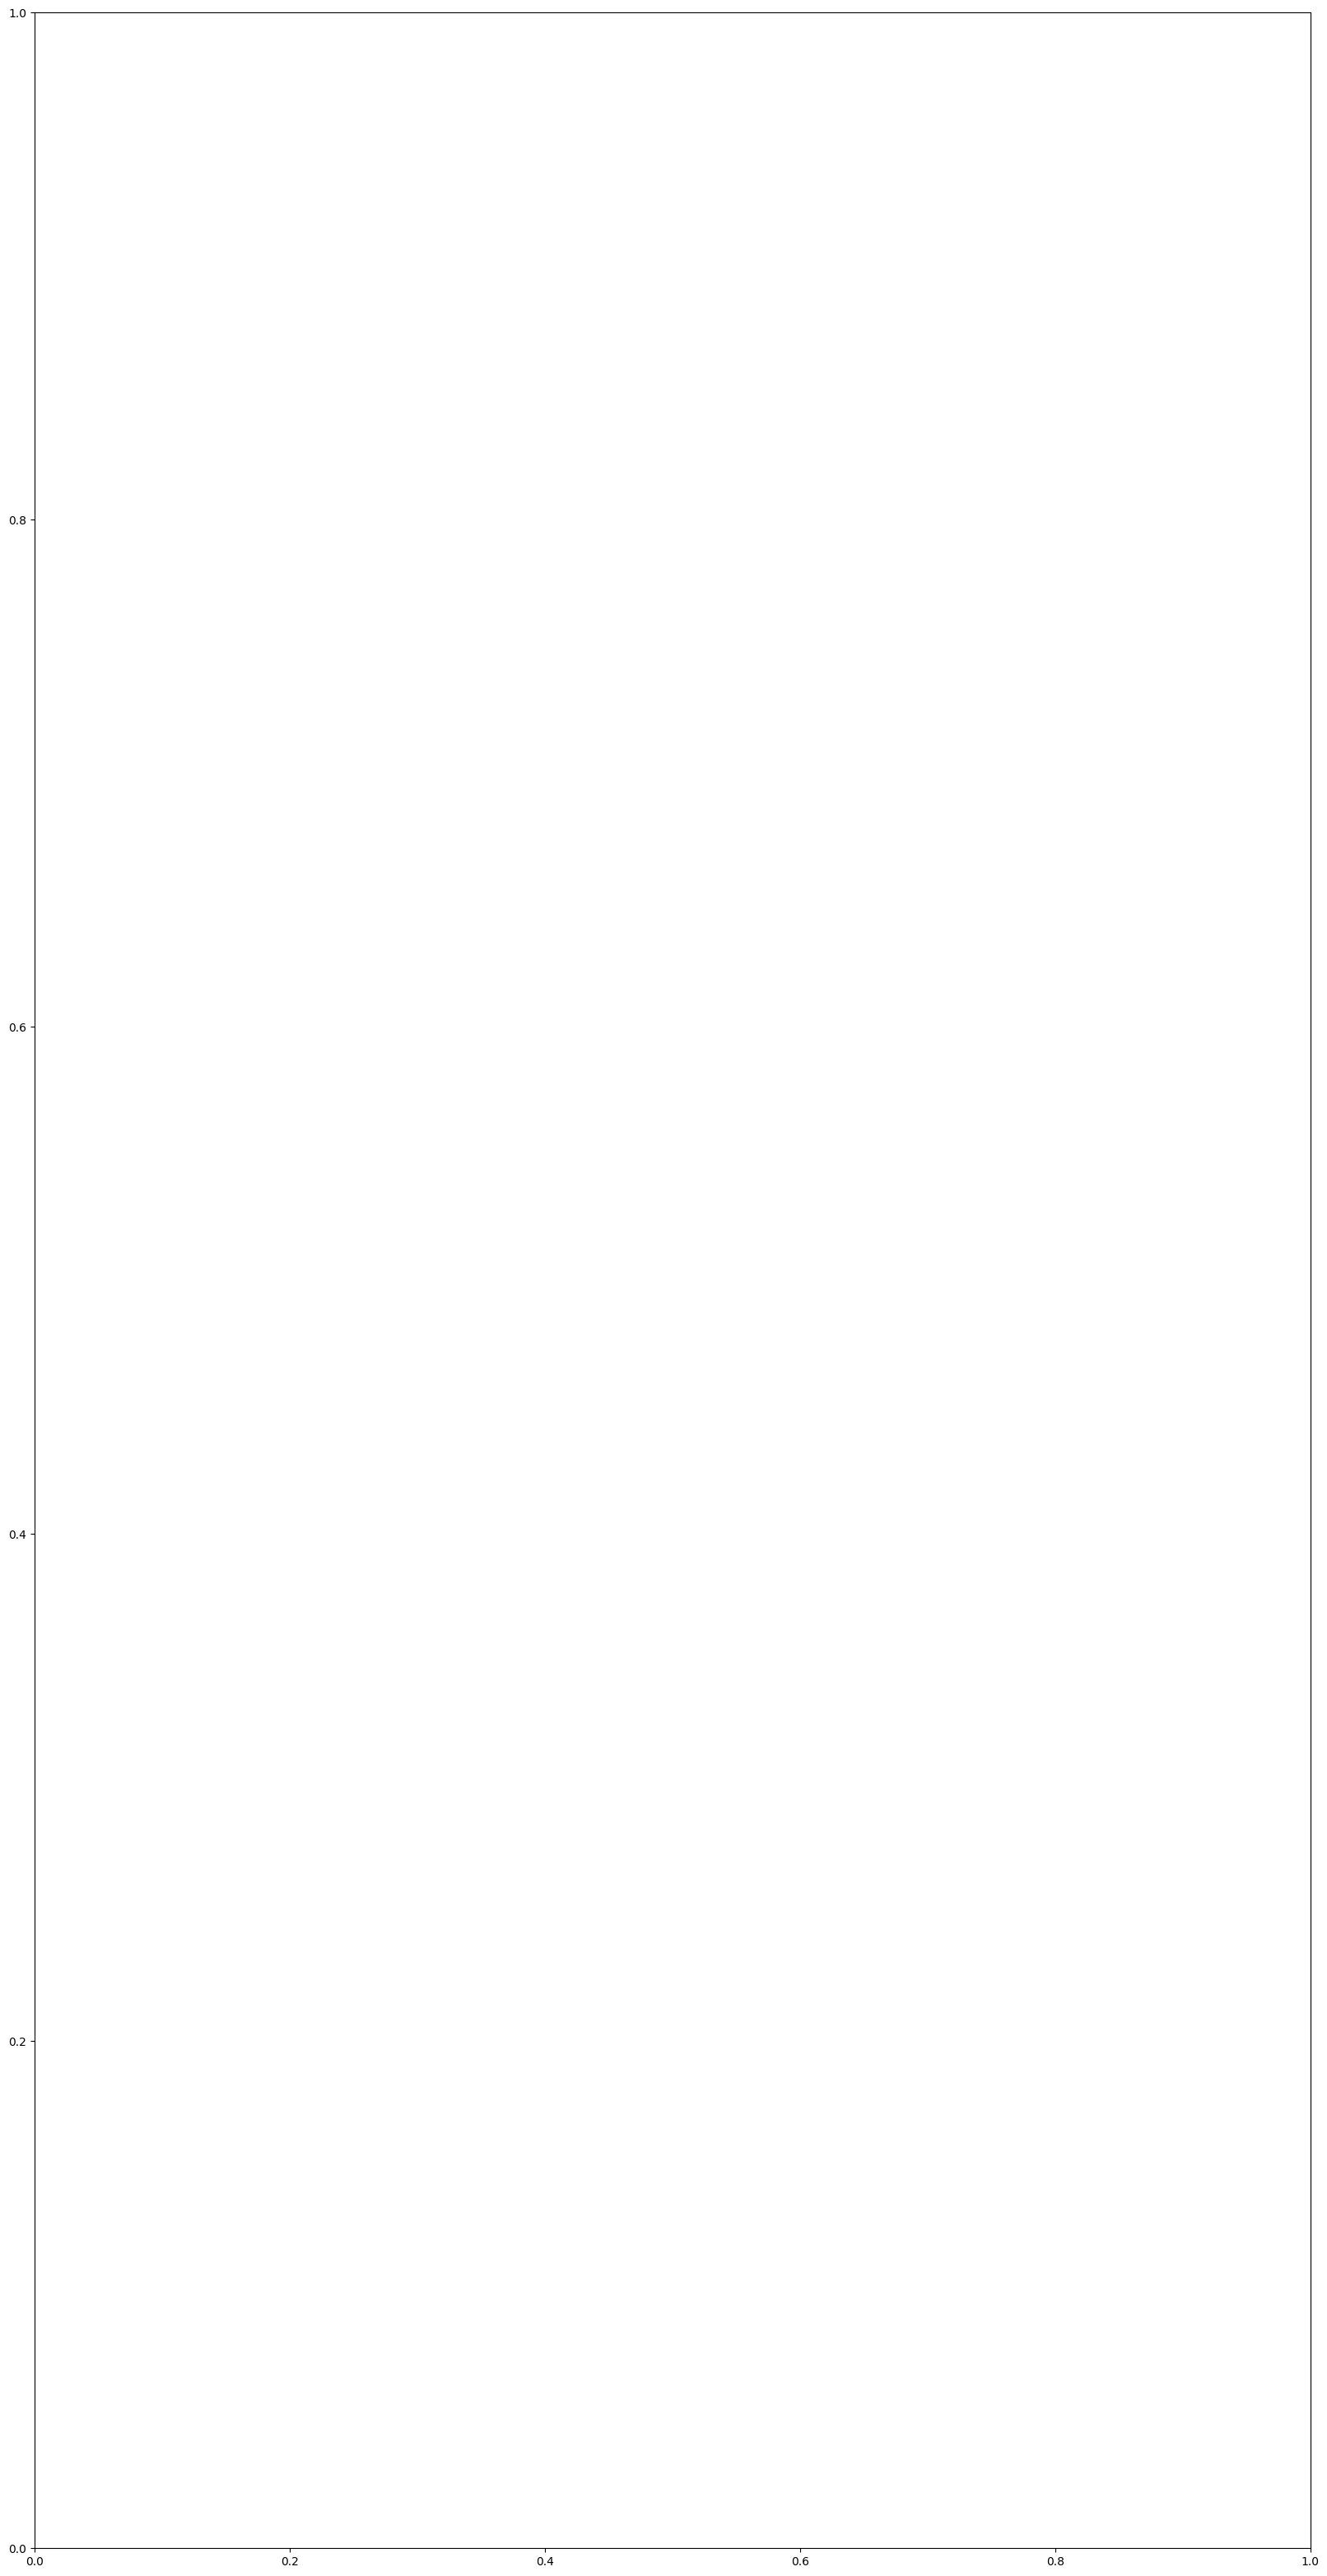

In [17]:
# Specify the size of the figure
fig, sx = plt.subplots(figsize = (20,40))
plt.show()

#### Adding Data to the axes

In [18]:
seattle["MONTH"]

0      Jan
1      Feb
2      Mar
3      Apr
4      May
      ... 
199    Aug
200    Sep
201    Oct
202    Nov
203    Dec
Name: MONTH, Length: 204, dtype: str

In [19]:
seattle["MLY-TAVG-NORMAL"]

0      39.3
1      40.7
2      43.8
3      47.4
4      53.1
       ... 
199    66.7
200    61.5
201    52.9
202    45.5
203    40.3
Name: MLY-TAVG-NORMAL, Length: 204, dtype: float64

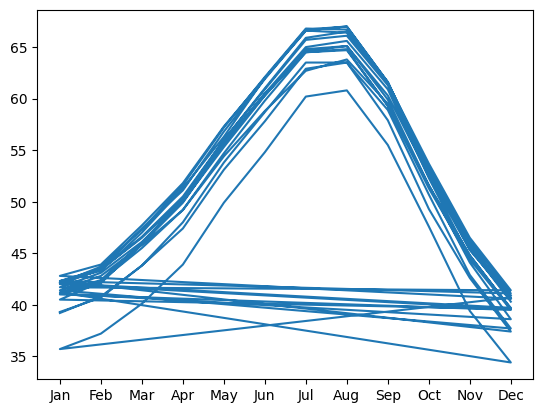

In [20]:
fig, sx = plt.subplots()
sx.plot(seattle["MONTH"], seattle["MLY-TAVG-NORMAL"])
plt.show()

In [21]:
# Subset the dataframe to only print for me the Month and the MLY-TAVG-NORMAL columns
seattle_subset = seattle[["MONTH", "MLY-TAVG-NORMAL"]]
seattle_subset.head(12)

,MONTH,MLY-TAVG-NORMAL
0,Jan,39.3
1,Feb,40.7
2,Mar,43.8
3,Apr,47.4
4,May,53.1
5,Jun,57.8
6,Jul,62.9
7,Aug,63.5
8,Sep,58.9
9,Oct,50.7


In [22]:
#To Solve this set the DATE column as the index column
seattle = seattle.set_index("DATE")
seattle.head()

,STATION,NAME,MLY-CLDD-BASE45,MLY-CLDD-BASE50,MLY-CLDD-BASE55,MLY-CLDD-BASE57,MLY-CLDD-BASE60,MLY-CLDD-BASE70,MLY-CLDD-BASE72,MLY-CLDD-NORMAL,...,MLY-TMIN-AVGNDS-LSTH070,MLY-TMIN-NORMAL,MLY-TMIN-PRBOCC-LSTH016,MLY-TMIN-PRBOCC-LSTH020,MLY-TMIN-PRBOCC-LSTH024,MLY-TMIN-PRBOCC-LSTH028,MLY-TMIN-PRBOCC-LSTH032,MLY-TMIN-PRBOCC-LSTH036,MLY-TMIN-STDDEV,MONTH
DATE,,,,,,,,,,,,,,,,,,,,,
1,USC00456295,"PALMER 3 ESE, WA US",13.0,1.0,-7777.0,0.0,0.0,0.0,0.0,0.0,...,310.0,34.0,168.0,327.0,615.0,877.0,987.0,1000.0,2.8,Jan
2,USC00456295,"PALMER 3 ESE, WA US",23.0,3.0,-7777.0,-7777.0,0.0,0.0,0.0,0.0,...,280.0,33.9,132.0,275.0,515.0,800.0,963.0,1000.0,3.1,Feb
3,USC00456295,"PALMER 3 ESE, WA US",50.0,11.0,1.0,-7777.0,-7777.0,0.0,0.0,0.0,...,310.0,35.9,5.0,47.0,111.0,393.0,848.0,1000.0,2.1,Mar
4,USC00456295,"PALMER 3 ESE, WA US",108.0,40.0,12.0,7.0,3.0,-7777.0,0.0,-7777.0,...,300.0,38.3,0.0,0.0,5.0,123.0,571.0,978.0,2.0,Apr
5,USC00456295,"PALMER 3 ESE, WA US",255.0,130.0,56.0,38.0,19.0,1.0,-7777.0,5.0,...,310.0,43.5,0.0,0.0,0.0,0.0,83.0,610.0,2.0,May


In [23]:
# Slice the Data only include the first 12 rows which correspond to the 12 months of the year
seattle_sliced = seattle.iloc[:12]
seattle_sliced


,STATION,NAME,MLY-CLDD-BASE45,MLY-CLDD-BASE50,MLY-CLDD-BASE55,MLY-CLDD-BASE57,MLY-CLDD-BASE60,MLY-CLDD-BASE70,MLY-CLDD-BASE72,MLY-CLDD-NORMAL,...,MLY-TMIN-AVGNDS-LSTH070,MLY-TMIN-NORMAL,MLY-TMIN-PRBOCC-LSTH016,MLY-TMIN-PRBOCC-LSTH020,MLY-TMIN-PRBOCC-LSTH024,MLY-TMIN-PRBOCC-LSTH028,MLY-TMIN-PRBOCC-LSTH032,MLY-TMIN-PRBOCC-LSTH036,MLY-TMIN-STDDEV,MONTH
DATE,,,,,,,,,,,,,,,,,,,,,
1,USC00456295,"PALMER 3 ESE, WA US",13.0,1.0,-7777.0,0.0,0.0,0.0,0.0,0.0,...,310.0,34.0,168.0,327.0,615.0,877.0,987.0,1000.0,2.8,Jan
2,USC00456295,"PALMER 3 ESE, WA US",23.0,3.0,-7777.0,-7777.0,0.0,0.0,0.0,0.0,...,280.0,33.9,132.0,275.0,515.0,800.0,963.0,1000.0,3.1,Feb
3,USC00456295,"PALMER 3 ESE, WA US",50.0,11.0,1.0,-7777.0,-7777.0,0.0,0.0,0.0,...,310.0,35.9,5.0,47.0,111.0,393.0,848.0,1000.0,2.1,Mar
4,USC00456295,"PALMER 3 ESE, WA US",108.0,40.0,12.0,7.0,3.0,-7777.0,0.0,-7777.0,...,300.0,38.3,0.0,0.0,5.0,123.0,571.0,978.0,2.0,Apr
5,USC00456295,"PALMER 3 ESE, WA US",255.0,130.0,56.0,38.0,19.0,1.0,-7777.0,5.0,...,310.0,43.5,0.0,0.0,0.0,0.0,83.0,610.0,2.0,May
6,USC00456295,"PALMER 3 ESE, WA US",384.0,237.0,115.0,80.0,45.0,3.0,1.0,14.0,...,300.0,48.0,0.0,0.0,0.0,0.0,0.0,36.0,1.8,Jun
7,USC00456295,"PALMER 3 ESE, WA US",553.0,398.0,246.0,190.0,118.0,10.0,5.0,41.0,...,310.0,51.9,0.0,0.0,0.0,0.0,0.0,0.0,1.7,Jul
8,USC00456295,"PALMER 3 ESE, WA US",573.0,418.0,265.0,206.0,130.0,9.0,5.0,46.0,...,310.0,52.4,0.0,0.0,0.0,0.0,0.0,0.0,1.4,Aug
9,USC00456295,"PALMER 3 ESE, WA US",417.0,270.0,142.0,102.0,57.0,3.0,1.0,15.0,...,300.0,48.6,0.0,0.0,0.0,0.0,4.0,79.0,1.9,Sep


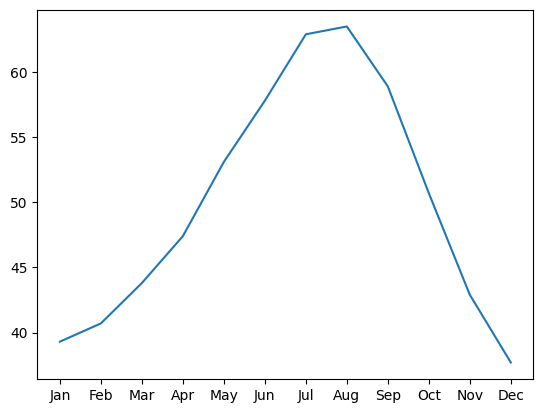

In [24]:
# Let's now solve the issue we had up there
fig, sx = plt.subplots()
sx.plot(seattle_sliced["MONTH"], seattle_sliced["MLY-TAVG-NORMAL"])
plt.show()

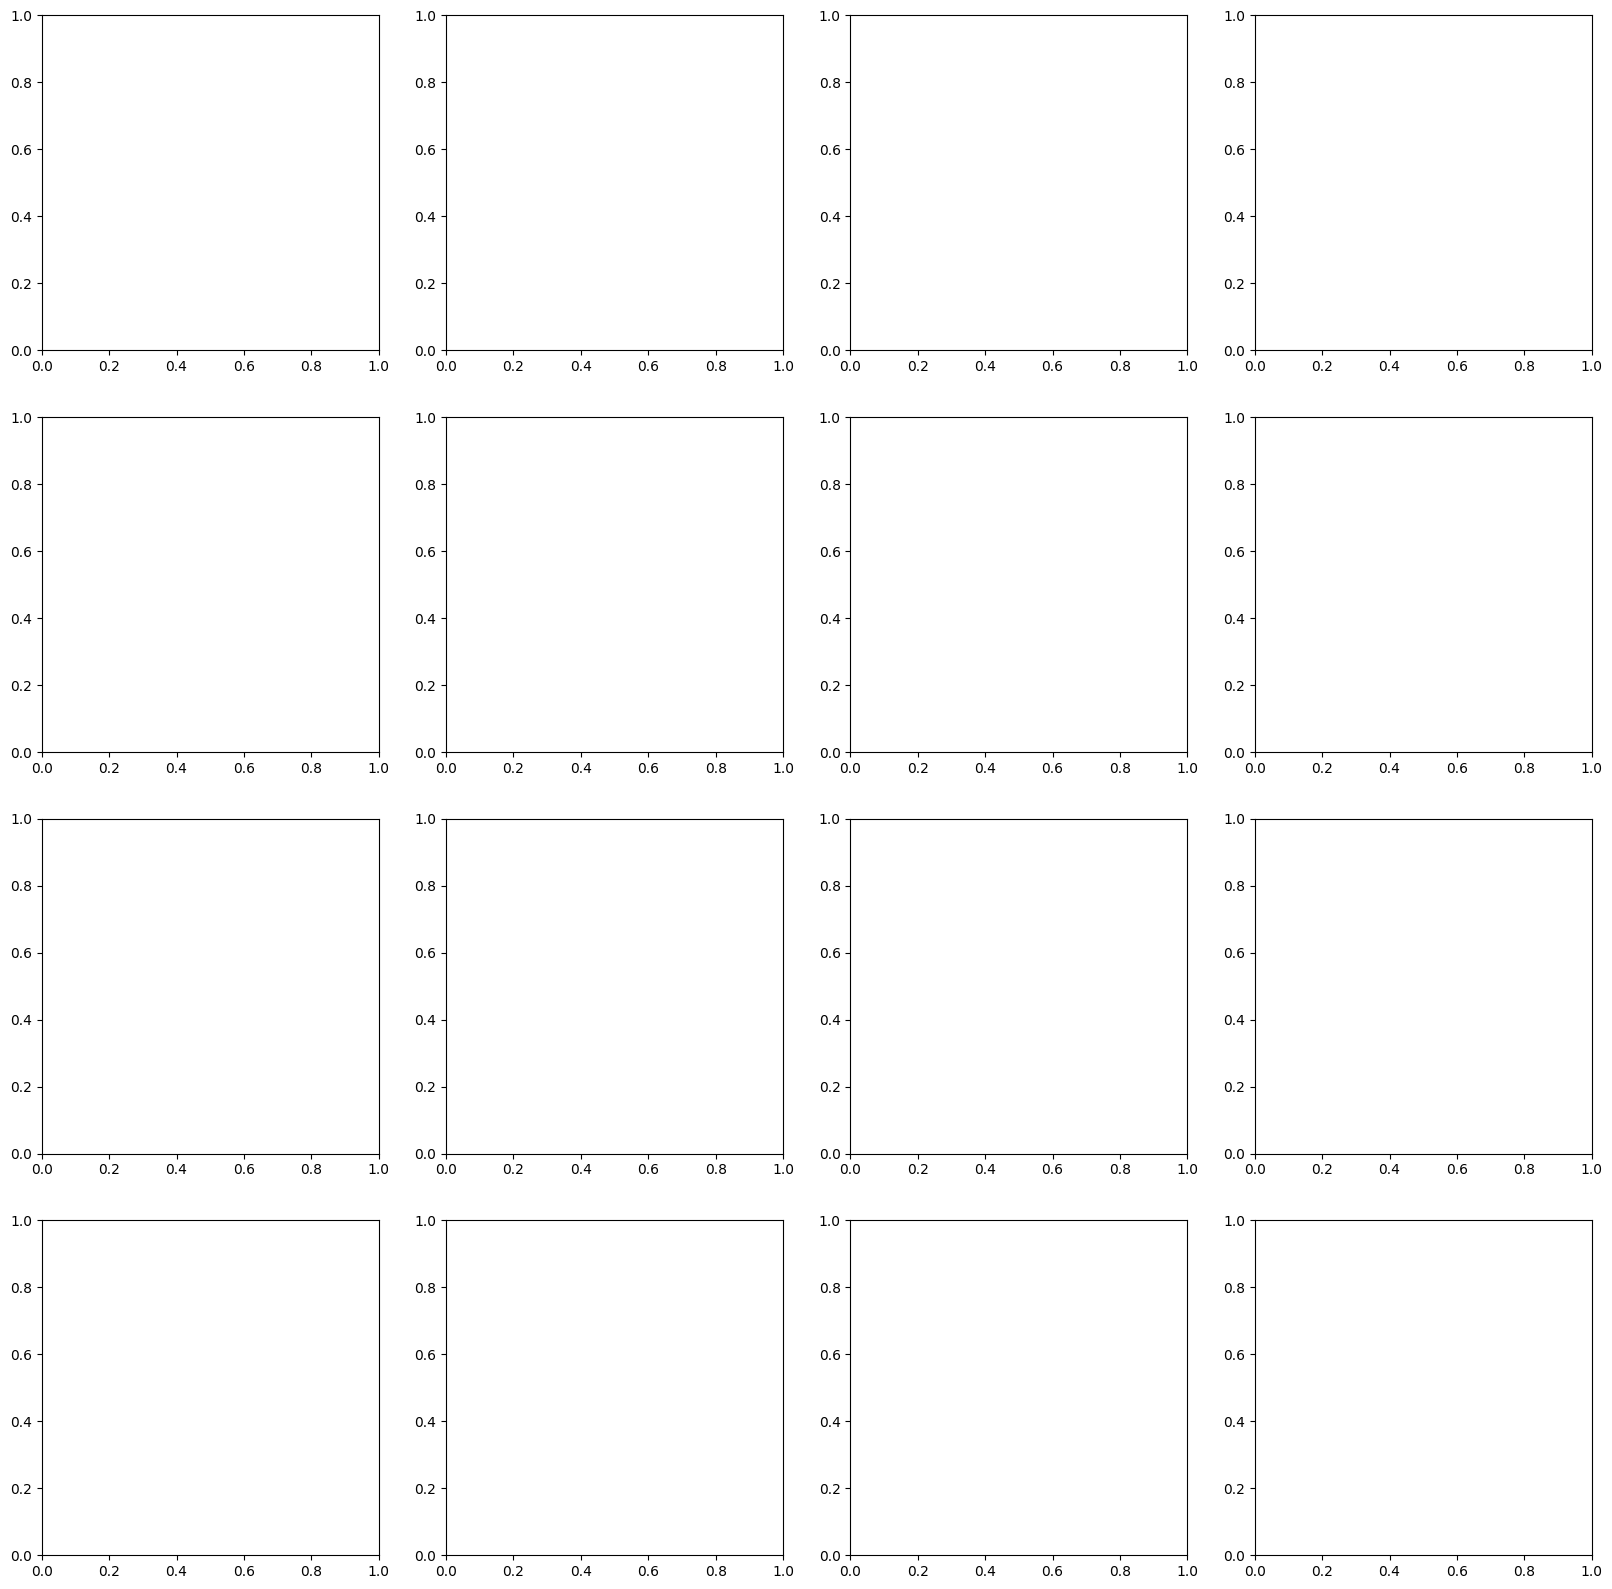

In [25]:
fig, sx = plt.subplots(4,4, figsize=(20, 20))


#### `Assignment`:

 Now plot the same graph for at least four other years in your dataset and compare the results.

In [26]:
seattle_subset = seattle[["MONTH", "MLY-TAVG-NORMAL"]]
seattle_subset.head(48)

,MONTH,MLY-TAVG-NORMAL
DATE,,
1,Jan,39.3
2,Feb,40.7
3,Mar,43.8
4,Apr,47.4
5,May,53.1
6,Jun,57.8
7,Jul,62.9
8,Aug,63.5
9,Sep,58.9


In [27]:
seattle_sliced_4 = seattle.iloc[:48]
seattle_sliced_4

,STATION,NAME,MLY-CLDD-BASE45,MLY-CLDD-BASE50,MLY-CLDD-BASE55,MLY-CLDD-BASE57,MLY-CLDD-BASE60,MLY-CLDD-BASE70,MLY-CLDD-BASE72,MLY-CLDD-NORMAL,...,MLY-TMIN-AVGNDS-LSTH070,MLY-TMIN-NORMAL,MLY-TMIN-PRBOCC-LSTH016,MLY-TMIN-PRBOCC-LSTH020,MLY-TMIN-PRBOCC-LSTH024,MLY-TMIN-PRBOCC-LSTH028,MLY-TMIN-PRBOCC-LSTH032,MLY-TMIN-PRBOCC-LSTH036,MLY-TMIN-STDDEV,MONTH
DATE,,,,,,,,,,,,,,,,,,,,,
1,USC00456295,"PALMER 3 ESE, WA US",13.0,1.0,-7777.0,0.0,0.0,0.0,0.0,0.0,...,310.0,34.0,168.0,327.0,615.0,877.0,987.0,1000.0,2.8,Jan
2,USC00456295,"PALMER 3 ESE, WA US",23.0,3.0,-7777.0,-7777.0,0.0,0.0,0.0,0.0,...,280.0,33.9,132.0,275.0,515.0,800.0,963.0,1000.0,3.1,Feb
3,USC00456295,"PALMER 3 ESE, WA US",50.0,11.0,1.0,-7777.0,-7777.0,0.0,0.0,0.0,...,310.0,35.9,5.0,47.0,111.0,393.0,848.0,1000.0,2.1,Mar
4,USC00456295,"PALMER 3 ESE, WA US",108.0,40.0,12.0,7.0,3.0,-7777.0,0.0,-7777.0,...,300.0,38.3,0.0,0.0,5.0,123.0,571.0,978.0,2.0,Apr
5,USC00456295,"PALMER 3 ESE, WA US",255.0,130.0,56.0,38.0,19.0,1.0,-7777.0,5.0,...,310.0,43.5,0.0,0.0,0.0,0.0,83.0,610.0,2.0,May
6,USC00456295,"PALMER 3 ESE, WA US",384.0,237.0,115.0,80.0,45.0,3.0,1.0,14.0,...,300.0,48.0,0.0,0.0,0.0,0.0,0.0,36.0,1.8,Jun
7,USC00456295,"PALMER 3 ESE, WA US",553.0,398.0,246.0,190.0,118.0,10.0,5.0,41.0,...,310.0,51.9,0.0,0.0,0.0,0.0,0.0,0.0,1.7,Jul
8,USC00456295,"PALMER 3 ESE, WA US",573.0,418.0,265.0,206.0,130.0,9.0,5.0,46.0,...,310.0,52.4,0.0,0.0,0.0,0.0,0.0,0.0,1.4,Aug
9,USC00456295,"PALMER 3 ESE, WA US",417.0,270.0,142.0,102.0,57.0,3.0,1.0,15.0,...,300.0,48.6,0.0,0.0,0.0,0.0,4.0,79.0,1.9,Sep


In [28]:
seattle_sliced_Year_1 = seattle.iloc[0:12]
seattle_sliced_Year_1

,STATION,NAME,MLY-CLDD-BASE45,MLY-CLDD-BASE50,MLY-CLDD-BASE55,MLY-CLDD-BASE57,MLY-CLDD-BASE60,MLY-CLDD-BASE70,MLY-CLDD-BASE72,MLY-CLDD-NORMAL,...,MLY-TMIN-AVGNDS-LSTH070,MLY-TMIN-NORMAL,MLY-TMIN-PRBOCC-LSTH016,MLY-TMIN-PRBOCC-LSTH020,MLY-TMIN-PRBOCC-LSTH024,MLY-TMIN-PRBOCC-LSTH028,MLY-TMIN-PRBOCC-LSTH032,MLY-TMIN-PRBOCC-LSTH036,MLY-TMIN-STDDEV,MONTH
DATE,,,,,,,,,,,,,,,,,,,,,
1,USC00456295,"PALMER 3 ESE, WA US",13.0,1.0,-7777.0,0.0,0.0,0.0,0.0,0.0,...,310.0,34.0,168.0,327.0,615.0,877.0,987.0,1000.0,2.8,Jan
2,USC00456295,"PALMER 3 ESE, WA US",23.0,3.0,-7777.0,-7777.0,0.0,0.0,0.0,0.0,...,280.0,33.9,132.0,275.0,515.0,800.0,963.0,1000.0,3.1,Feb
3,USC00456295,"PALMER 3 ESE, WA US",50.0,11.0,1.0,-7777.0,-7777.0,0.0,0.0,0.0,...,310.0,35.9,5.0,47.0,111.0,393.0,848.0,1000.0,2.1,Mar
4,USC00456295,"PALMER 3 ESE, WA US",108.0,40.0,12.0,7.0,3.0,-7777.0,0.0,-7777.0,...,300.0,38.3,0.0,0.0,5.0,123.0,571.0,978.0,2.0,Apr
5,USC00456295,"PALMER 3 ESE, WA US",255.0,130.0,56.0,38.0,19.0,1.0,-7777.0,5.0,...,310.0,43.5,0.0,0.0,0.0,0.0,83.0,610.0,2.0,May
6,USC00456295,"PALMER 3 ESE, WA US",384.0,237.0,115.0,80.0,45.0,3.0,1.0,14.0,...,300.0,48.0,0.0,0.0,0.0,0.0,0.0,36.0,1.8,Jun
7,USC00456295,"PALMER 3 ESE, WA US",553.0,398.0,246.0,190.0,118.0,10.0,5.0,41.0,...,310.0,51.9,0.0,0.0,0.0,0.0,0.0,0.0,1.7,Jul
8,USC00456295,"PALMER 3 ESE, WA US",573.0,418.0,265.0,206.0,130.0,9.0,5.0,46.0,...,310.0,52.4,0.0,0.0,0.0,0.0,0.0,0.0,1.4,Aug
9,USC00456295,"PALMER 3 ESE, WA US",417.0,270.0,142.0,102.0,57.0,3.0,1.0,15.0,...,300.0,48.6,0.0,0.0,0.0,0.0,4.0,79.0,1.9,Sep


In [29]:
seattle_sliced_Year_2 = seattle.iloc[12:24]
seattle_sliced_Year_2

,STATION,NAME,MLY-CLDD-BASE45,MLY-CLDD-BASE50,MLY-CLDD-BASE55,MLY-CLDD-BASE57,MLY-CLDD-BASE60,MLY-CLDD-BASE70,MLY-CLDD-BASE72,MLY-CLDD-NORMAL,...,MLY-TMIN-AVGNDS-LSTH070,MLY-TMIN-NORMAL,MLY-TMIN-PRBOCC-LSTH016,MLY-TMIN-PRBOCC-LSTH020,MLY-TMIN-PRBOCC-LSTH024,MLY-TMIN-PRBOCC-LSTH028,MLY-TMIN-PRBOCC-LSTH032,MLY-TMIN-PRBOCC-LSTH036,MLY-TMIN-STDDEV,MONTH
DATE,,,,,,,,,,,,,,,,,,,,,
1,USW00024222,"EVERETT SNOHOMISH CO AIRPORT, WA US",26.0,4.0,-7777.0,0.0,0.0,0.0,0.0,0.0,...,310.0,37.0,81.0,183.0,398.0,730.0,959.0,999.0,2.9,Jan
2,USW00024222,"EVERETT SNOHOMISH CO AIRPORT, WA US",25.0,2.0,-7777.0,-7777.0,0.0,0.0,0.0,0.0,...,280.0,37.2,19.0,79.0,246.0,561.0,873.0,994.0,3.0,Feb
3,USW00024222,"EVERETT SNOHOMISH CO AIRPORT, WA US",72.0,16.0,2.0,1.0,-7777.0,0.0,0.0,-7777.0,...,310.0,39.6,0.0,15.0,52.0,181.0,616.0,977.0,2.0,Mar
4,USW00024222,"EVERETT SNOHOMISH CO AIRPORT, WA US",137.0,45.0,10.0,5.0,1.0,0.0,0.0,-7777.0,...,300.0,42.5,0.0,0.0,0.0,0.0,143.0,692.0,1.8,Apr
5,USW00024222,"EVERETT SNOHOMISH CO AIRPORT, WA US",293.0,149.0,50.0,29.0,11.0,1.0,-7777.0,2.0,...,310.0,47.2,0.0,0.0,0.0,0.0,0.0,91.0,1.9,May
6,USW00024222,"EVERETT SNOHOMISH CO AIRPORT, WA US",414.0,264.0,128.0,84.0,40.0,2.0,1.0,9.0,...,300.0,51.4,0.0,0.0,0.0,0.0,0.0,0.0,1.3,Jun
7,USW00024222,"EVERETT SNOHOMISH CO AIRPORT, WA US",549.0,394.0,239.0,180.0,102.0,7.0,4.0,28.0,...,309.0,54.6,0.0,0.0,0.0,0.0,0.0,0.0,1.5,Jul
8,USW00024222,"EVERETT SNOHOMISH CO AIRPORT, WA US",581.0,426.0,271.0,210.0,123.0,4.0,2.0,28.0,...,310.0,55.1,0.0,0.0,0.0,0.0,0.0,0.0,1.0,Aug
9,USW00024222,"EVERETT SNOHOMISH CO AIRPORT, WA US",435.0,285.0,144.0,97.0,46.0,-7777.0,-7777.0,7.0,...,300.0,52.0,0.0,0.0,0.0,0.0,0.0,0.0,1.3,Sep


In [30]:
seattle_sliced_Year_3 = seattle.iloc[24:36]
seattle_sliced_Year_3

,STATION,NAME,MLY-CLDD-BASE45,MLY-CLDD-BASE50,MLY-CLDD-BASE55,MLY-CLDD-BASE57,MLY-CLDD-BASE60,MLY-CLDD-BASE70,MLY-CLDD-BASE72,MLY-CLDD-NORMAL,...,MLY-TMIN-AVGNDS-LSTH070,MLY-TMIN-NORMAL,MLY-TMIN-PRBOCC-LSTH016,MLY-TMIN-PRBOCC-LSTH020,MLY-TMIN-PRBOCC-LSTH024,MLY-TMIN-PRBOCC-LSTH028,MLY-TMIN-PRBOCC-LSTH032,MLY-TMIN-PRBOCC-LSTH036,MLY-TMIN-STDDEV,MONTH
DATE,,,,,,,,,,,,,,,,,,,,,
1,USW00024233,"SEATTLE TACOMA INTERNATIONAL AIRPORT, WA US",32.0,4.0,-7777.0,-7777.0,0.0,0.0,0.0,0.0,...,310.0,36.9,50.0,152.0,413.0,757.0,954.0,998.0,2.8,Jan
2,USW00024233,"SEATTLE TACOMA INTERNATIONAL AIRPORT, WA US",38.0,6.0,-7777.0,-7777.0,0.0,0.0,0.0,0.0,...,280.0,36.9,28.0,93.0,291.0,622.0,900.0,1000.0,2.9,Feb
3,USW00024233,"SEATTLE TACOMA INTERNATIONAL AIRPORT, WA US",83.0,18.0,2.0,1.0,-7777.0,0.0,0.0,-7777.0,...,310.0,39.3,0.0,5.0,40.0,167.0,613.0,973.0,2.0,Mar
4,USW00024233,"SEATTLE TACOMA INTERNATIONAL AIRPORT, WA US",166.0,62.0,17.0,9.0,3.0,-7777.0,0.0,-7777.0,...,300.0,42.2,0.0,0.0,0.0,0.0,79.0,682.0,1.6,Apr
5,USW00024233,"SEATTLE TACOMA INTERNATIONAL AIRPORT, WA US",341.0,192.0,81.0,53.0,25.0,1.0,-7777.0,6.0,...,310.0,47.3,0.0,0.0,0.0,0.0,0.0,51.0,1.7,May
6,USW00024233,"SEATTLE TACOMA INTERNATIONAL AIRPORT, WA US",477.0,327.0,182.0,130.0,70.0,6.0,3.0,21.0,...,300.0,51.9,0.0,0.0,0.0,0.0,0.0,0.0,1.3,Jun
7,USW00024233,"SEATTLE TACOMA INTERNATIONAL AIRPORT, WA US",642.0,487.0,332.0,270.0,181.0,20.0,12.0,71.0,...,310.0,55.6,0.0,0.0,0.0,0.0,0.0,0.0,1.6,Jul
8,USW00024233,"SEATTLE TACOMA INTERNATIONAL AIRPORT, WA US",654.0,499.0,344.0,282.0,191.0,17.0,8.0,70.0,...,310.0,55.9,0.0,0.0,0.0,0.0,0.0,0.0,1.1,Aug
9,USW00024233,"SEATTLE TACOMA INTERNATIONAL AIRPORT, WA US",489.0,339.0,194.0,143.0,81.0,3.0,1.0,21.0,...,300.0,52.1,0.0,0.0,0.0,0.0,0.0,0.0,1.4,Sep


In [31]:
seattle_sliced_Year_4 = seattle.iloc[36:48]
seattle_sliced_Year_4

,STATION,NAME,MLY-CLDD-BASE45,MLY-CLDD-BASE50,MLY-CLDD-BASE55,MLY-CLDD-BASE57,MLY-CLDD-BASE60,MLY-CLDD-BASE70,MLY-CLDD-BASE72,MLY-CLDD-NORMAL,...,MLY-TMIN-AVGNDS-LSTH070,MLY-TMIN-NORMAL,MLY-TMIN-PRBOCC-LSTH016,MLY-TMIN-PRBOCC-LSTH020,MLY-TMIN-PRBOCC-LSTH024,MLY-TMIN-PRBOCC-LSTH028,MLY-TMIN-PRBOCC-LSTH032,MLY-TMIN-PRBOCC-LSTH036,MLY-TMIN-STDDEV,MONTH
DATE,,,,,,,,,,,,,,,,,,,,,
1,USC00458278,"TACOMA NUMBER 1, WA US",40.0,6.0,1.0,-7777.0,0.0,0.0,0.0,0.0,...,310.0,37.1,74.0,162.0,424.0,779.0,964.0,998.0,2.7,Jan
2,USC00458278,"TACOMA NUMBER 1, WA US",43.0,6.0,-7777.0,-7777.0,0.0,0.0,0.0,0.0,...,280.0,36.9,17.0,99.0,312.0,672.0,947.0,1000.0,2.8,Feb
3,USC00458278,"TACOMA NUMBER 1, WA US",107.0,29.0,4.0,1.0,-7777.0,0.0,0.0,0.0,...,310.0,39.8,4.0,19.0,39.0,215.0,719.0,974.0,2.2,Mar
4,USC00458278,"TACOMA NUMBER 1, WA US",207.0,86.0,23.0,13.0,4.0,0.0,0.0,-7777.0,...,300.0,43.2,0.0,0.0,0.0,3.0,226.0,794.0,1.7,Apr
5,USC00458278,"TACOMA NUMBER 1, WA US",381.0,230.0,104.0,68.0,32.0,1.0,-7777.0,6.0,...,310.0,48.2,0.0,0.0,0.0,0.0,0.0,117.0,2.0,May
6,USC00458278,"TACOMA NUMBER 1, WA US",512.0,362.0,213.0,158.0,88.0,3.0,1.0,23.0,...,300.0,52.6,0.0,0.0,0.0,0.0,0.0,0.0,1.5,Jun
7,USC00458278,"TACOMA NUMBER 1, WA US",668.0,513.0,358.0,296.0,204.0,14.0,6.0,75.0,...,310.0,56.1,0.0,0.0,0.0,0.0,0.0,0.0,2.0,Jul
8,USC00458278,"TACOMA NUMBER 1, WA US",662.0,507.0,352.0,290.0,199.0,11.0,4.0,70.0,...,310.0,55.7,0.0,0.0,0.0,0.0,0.0,0.0,1.7,Aug
9,USC00458278,"TACOMA NUMBER 1, WA US",493.0,344.0,198.0,144.0,77.0,1.0,-7777.0,15.0,...,300.0,51.6,0.0,0.0,0.0,0.0,0.0,23.0,2.0,Sep


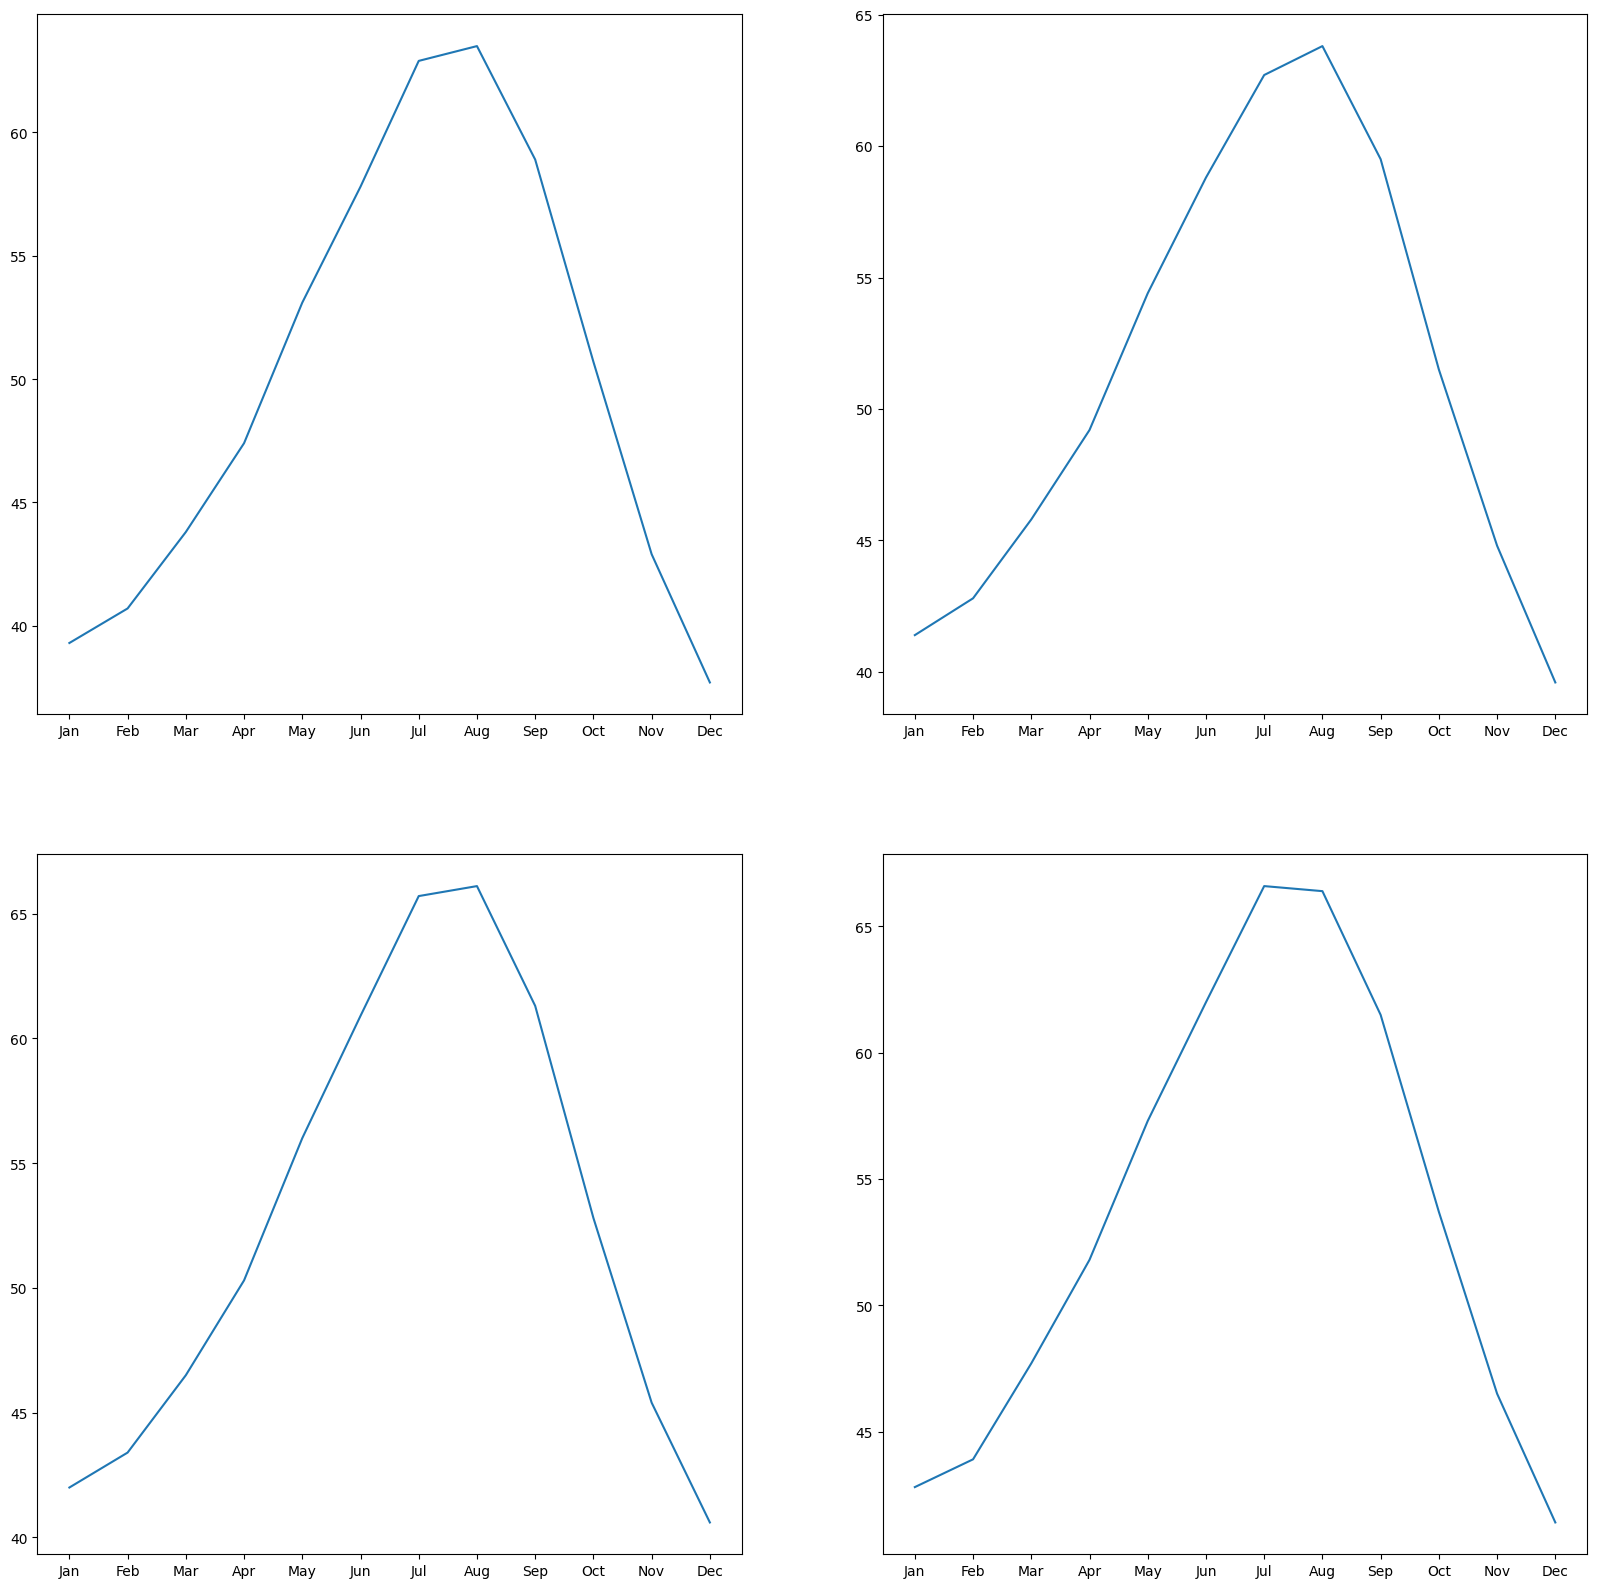

In [32]:
fig, sx = plt.subplots(2,2, figsize=(20,20))
sx[0, 0].plot(seattle_sliced_Year_1["MONTH"], seattle_sliced_Year_1["MLY-TAVG-NORMAL"])

sx[0, 1].plot(seattle_sliced_Year_2["MONTH"], seattle_sliced_Year_2["MLY-TAVG-NORMAL"])

sx[1, 0].plot(seattle_sliced_Year_3["MONTH"], seattle_sliced_Year_3["MLY-TAVG-NORMAL"])

sx[1, 1].plot(seattle_sliced_Year_4["MONTH"], seattle_sliced_Year_4["MLY-TAVG-NORMAL"])

plt.show()


Plotting the Seattle and Austin Precipitation Data in Two different plots 

##### Cleaning and EDA for Austin

In [33]:
austin.isna().sum()

STATION                    0
NAME                       0
DATE                       0
MLY-CLDD-BASE45            0
MLY-CLDD-BASE50            0
                          ..
MLY-TMIN-PRBOCC-LSTH024    0
MLY-TMIN-PRBOCC-LSTH028    0
MLY-TMIN-PRBOCC-LSTH032    0
MLY-TMIN-PRBOCC-LSTH036    0
MLY-TMIN-STDDEV            0
Length: 67, dtype: int64

In [34]:
austin.duplicated().sum()

np.int64(0)

In [35]:
austin.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 67 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   STATION                  12 non-null     str    
 1   NAME                     12 non-null     str    
 2   DATE                     12 non-null     int64  
 3   MLY-CLDD-BASE45          12 non-null     int64  
 4   MLY-CLDD-BASE50          12 non-null     int64  
 5   MLY-CLDD-BASE55          12 non-null     int64  
 6   MLY-CLDD-BASE57          12 non-null     int64  
 7   MLY-CLDD-BASE60          12 non-null     int64  
 8   MLY-CLDD-BASE70          12 non-null     int64  
 9   MLY-CLDD-BASE72          12 non-null     int64  
 10  MLY-CLDD-NORMAL          12 non-null     int64  
 11  MLY-DUTR-NORMAL          12 non-null     float64
 12  MLY-DUTR-STDDEV          12 non-null     float64
 13  MLY-GRDD-BASE40          12 non-null     int64  
 14  MLY-GRDD-BASE45          12 non-null   

In [36]:

austin["MONTH"] = austin["DATE"].apply(lambda x: calendar.month_abbr[x])

In [37]:
austin.head()

,STATION,NAME,DATE,MLY-CLDD-BASE45,MLY-CLDD-BASE50,MLY-CLDD-BASE55,MLY-CLDD-BASE57,MLY-CLDD-BASE60,MLY-CLDD-BASE70,MLY-CLDD-BASE72,...,MLY-TMIN-AVGNDS-LSTH070,MLY-TMIN-NORMAL,MLY-TMIN-PRBOCC-LSTH016,MLY-TMIN-PRBOCC-LSTH020,MLY-TMIN-PRBOCC-LSTH024,MLY-TMIN-PRBOCC-LSTH028,MLY-TMIN-PRBOCC-LSTH032,MLY-TMIN-PRBOCC-LSTH036,MLY-TMIN-STDDEV,MONTH
0,USW00013904,"AUSTIN BERGSTROM INTERNATIONAL AIRPORT, TX US",1,190,103,50,35,18,1,-7777,...,310,36.3,298,570,839,967,997,1000,2.9,Jan
1,USW00013904,"AUSTIN BERGSTROM INTERNATIONAL AIRPORT, TX US",2,228,132,68,49,29,3,1,...,280,39.4,103,327,614,867,973,999,3.2,Feb
2,USW00013904,"AUSTIN BERGSTROM INTERNATIONAL AIRPORT, TX US",3,446,306,185,146,98,13,6,...,308,46.6,10,73,242,494,761,928,3.6,Mar
3,USW00013904,"AUSTIN BERGSTROM INTERNATIONAL AIRPORT, TX US",4,668,519,373,318,240,53,32,...,287,54.7,0,0,0,48,189,453,4.1,Apr
4,USW00013904,"AUSTIN BERGSTROM INTERNATIONAL AIRPORT, TX US",5,936,781,626,564,471,181,134,...,250,63.7,0,0,0,0,0,0,2.5,May


## Matplotlib and Seaborn

### Seaborn vs Matplotlib

In [38]:
# Example
# Create some data

rng = np.random.RandomState(0)
x = np.linspace(0, 10, 500)
y = np.cumsum(rng.radn(500, 6), 0)

AttributeError: 'numpy.random.mtrand.RandomState' object has no attribute 'radn'